# 033-optimised__mu_sigma — GM record selection, AvgSA([0, 3]), moment-objective selection `__mu_sigma` — Stage 2 (post-processing)

The post-processing of nb `032-…-optimised__mu_sigma`, identical to nb `033-…-optimised` except for
where it reads and writes, how the selection context is built, and the acceptance test. Loads the
complete `AvgSA_03_final_ensembles.pickle` **from this selection's folder** and writes the
per-`(site, iml)` stripe pickles + `.manifest.json` sidecars **into this selection's result
folder**. A stripe whose manifest already matches its fingerprint (computed with `SCHEME` =
`SELECTION_CONFIG_MU_SIGMA`) is left untouched. Runs in seconds.

**Same fingerprint as nb 032.** The selection context is built with
`setup_AvgSA03_gcim_gm_selection_for_scheme(SCHEME, sites=())`, so it carries the scheme's Ds5-95
weight (0.40, from the scheme config — never typed here) and its objective. With the plain setup
function (weight 0.25) every stripe would read as stale; `stripe_fingerprints` refuses such a
context.

**Acceptance `"complete_set"`**: every stripe with a full record set is written, whether or
not it passes KS (`ks_passed` stays in the stripe as a diagnostic; the number of KS-failing
stripes is printed). Only a stripe with no set at all is skipped ("No valid ensemble").

**Kept apart from the other selections.** Everything this notebook writes goes to
`config.ss_dir(cfg, "proc_data", "gm_selection", "AvgSA_03__opt_mu_sigma")` (`data_processed/06_gm_selection/AvgSA_03_optimised__mu_sigma/`)
and `config.ss_dir(cfg, "results", "record_selection", "AvgSA_03__opt_mu_sigma")`
(`results/04_record_selection/AvgSA_03_optimised__mu_sigma/`), under the same file names as the original.

**Excluded records** — the stale check is versioned by the exclusion list, exactly as in the other
selections. A stale stripe for which nb 032 found no acceptable ensemble stops the notebook if its
old pickle is still on disk, so its old records cannot reach the download lists.

**Upstream**:
- `AvgSA_03_final_ensembles.pickle` (+ manifest) in `config.ss_dir(cfg, "proc_data", "gm_selection", "AvgSA_03__opt_mu_sigma")`.
- `gcim_dist_AvgSA_03.pickle` (nb `031`, shared) — for `gcim_quantiles`.
- `setup_AvgSA03_gcim_gm_selection_for_scheme(SCHEME, sites=())` — selection context only; no disagg shard is opened.

**Output** (all in this selection's folders, same file names as nb `033`):
- Per-`(site, iml)` stripe pickles `site_{id}__stripe_iml_{iml}__gm_selection.pickle` (+ manifest)
  in `config.ss_dir(cfg, "results", "record_selection", "AvgSA_03__opt_mu_sigma")`.
- `AvgSA_03_summary_esm_records_selected.csv`, `AvgSA_03_summary_ngasub_records_selected.csv`,
  `AvgSA_03_records_to_convert.csv` in `config.ss_dir(cfg, "proc_data", "gm_selection", "AvgSA_03__opt_mu_sigma")`.

**Run order** — run top to bottom after `032-…-optimised__mu_sigma`; safe to re-run.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

from phd_project.config import config
from phd_project.config.config import load_config
from phd_project.scripts.cache_utils import fingerprint, verify, write_manifest
from phd_project.scripts.disagg_shards import shards_digest
from phd_project.scripts.WP1_ground_motion_set.gm_selection import (
    get_poe_from_disaggstats, iml_filename_tag,
    stripe_pickle_path, find_stale_stripes,
    ensemble_accepted, normalise_selection_scheme,
    _selection_ctx_fingerprint_inputs)
# NOTE: SELECTION_CONFIG_MU_SIGMA (used below as SCHEME), NOT another selection's config.
from phd_project.scripts.WP1_ground_motion_set.setup_AvgSA03_gm_selection import (
    setup_AvgSA03_gcim_gm_selection_for_scheme, wanted_stripe_keys, SELECTION_CONFIG_MU_SIGMA,
    stripe_source_fps, stripe_fingerprints)

cfg = load_config()
# SIDE QUEST (see side-quest_gm_selection_optimisation/README.md). This notebook belongs to
# ONE record set, pinned here - not the active study - so re-running it only ever touches
# that set's folders. GRID is the set's stripe grid from config.yaml: the LIVE grid since
# 2026-10-29 (the set is reselected on the rebuilt database). The frozen grid it was first
# selected on is kept in 06_gm_selection/ss/AvgSA_03__ks/imls_for_selection_AvgSA_03.json.
SS = "AvgSA_03__opt_mu_sigma"
GRID = config.stripe_grid_path(cfg, SS)

# THE selection scheme (the same constant nb 032 uses, so the fingerprints agree).
SCHEME = SELECTION_CONFIG_MU_SIGMA

# paths: every OUTPUT is in the optimised folders. The GCIM file and the disagg inputs
# are the shared originals (read only).
GMS = config.ss_dir(cfg, "proc_data", "gm_selection", SS)
gcim_dist_fp = cfg["proc_data"]["gcim_dists"] / "gcim_dist_AvgSA_03.pickle"
final_ensembles_fp = GMS / "AvgSA_03_final_ensembles.pickle"
esm_records_selected_fp = GMS / "AvgSA_03_summary_esm_records_selected.csv"
ngasub_records_selected_fp = GMS / "AvgSA_03_summary_ngasub_records_selected.csv"
records_to_convert_fp = GMS / "AvgSA_03_records_to_convert.csv"
disagg_stats_fp = cfg["proc_data"]["AvgSA_03_disagg_stats_gm_selection"]
disagg_shard_dir = cfg["proc_data"]["AvgSA_03_disagg_data_shards"]
RESULT_FOLDER = config.ss_dir(cfg, "results", "record_selection", SS)
RESULT_FOLDER.mkdir(parents=True, exist_ok=True)

# The selection context (for the per-stripe fingerprint) comes from setup, with
# sites=() so NO disagg shard is opened. The returned gm_db is not needed here.
# _for_scheme(SCHEME, ...): it carries the scheme's Ds5-95 weight (0.40) and objective,
# exactly as in nb 032, so the fingerprints match; the plain setup function would give
# weight 0.25 and stripe_fingerprints below would refuse the context.
_, disagg_stats, site_model, basic_selection_ctx, _ = setup_AvgSA03_gcim_gm_selection_for_scheme(SCHEME, sites=(), imls_for_selection_fp=GRID)
wanted = wanted_stripe_keys(imls_for_selection_fp=GRID)
source_fps_stripe = stripe_source_fps()
# Versioned by exclusion list -- the same stale check as nb 032-optimised__mu_sigma (see
# setup_AvgSA03_gm_selection.stripe_fingerprints). fp_fn is the CURRENT fingerprint, the
# one every manifest written below records.
fp_fn, superseded = stripe_fingerprints(
    SCHEME, source_fps_stripe, basic_selection_ctx, disagg_stats)

# load the complete set from nb 032-optimised__mu_sigma, plus the (shared) gcim
with open(final_ensembles_fp, "rb") as f:
    final_ensembles = pickle.load(f)
with open(gcim_dist_fp, "rb") as f:
    gcim_dists = pickle.load(f)

# The batch-artifact provenance check (verify on final_ensembles) is in the next code
# cell: it only runs when there is something to write from final_ensembles.

# Provenance stamp for the download/convert CSVs written below.
csv_provenance = fingerprint(final_ensembles=final_ensembles_fp)

C:\Users\clemettn\Documents\phd\phd_project\scripts\WP1_ground_motion_set\gm_selection.py:15: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


Built 0 (site, iml) disaggregations across 0 sites (0 of 60 shards loaded; 532 (site, iml) wanted in total).


## Save (re)selected per-(site, iml) stripes + surface record identifiers

Writes only the stale/new stripes (each with a `.manifest.json` that makes it a valid cache entry),
prunes any stripe whose `(site, iml)` is no longer in the union lists, then aggregates record
identifiers across **all** stripes on disk.

In [3]:
# Save the (re)selected stripes into the results folder. Each stripe pickle carries a
# .manifest.json (its per-stripe fingerprint) which IS the incremental cache: a stripe
# whose manifest already matches is left untouched. final_ensembles is the COMPLETE set,
# so we only (re)write the stale/new stripes; writing the manifest marks a stripe "valid".
DISAGG_IMT = "AvgSA"  # conditioning IM name used to look up the poe metadata

to_compute, valid = find_stale_stripes(wanted, RESULT_FOLDER, fp_fn, superseded=superseded)
print(f"{len(valid)} stripe(s) already valid on disk; (re)writing {len(to_compute)}.")

# Refuse to post-process a stale batch artifact: confirm the source files that produced
# final_ensembles are unchanged (hashes only -- nothing heavy is loaded). final_ensembles
# spans every site in its batch, so its disagg input is the whole-shard-set digest.
# db_exclusions is also checked, so a final-ensembles file built WITHOUT the database
# filter (or with a different exclusion list) is refused.
#
# Checked only when there is something to write. nb 032-optimised__mu_sigma rewrites the final-ensembles
# manifest whenever it selects a batch, so the manifest describes the LAST batch selected.
# On a run with nothing to (re)write it may legitimately predate the current inputs (e.g.
# the exclusion list grew without making any stripe of this selection stale), and
# checking it would refuse a run that consumes nothing from it.
if to_compute:
    verify(final_ensembles_fp, fingerprint(
        gm_db_file=cfg["proc_data"]["gm_database"],
        gcim_file=gcim_dist_fp,
        disagg_shards_digest=shards_digest(disagg_shard_dir),
        disagg_stats_file=disagg_stats_fp,
        site_model_file=cfg["hazard_models"]["eshm20_wp1_site_model"],
        db_exclusions=repr(SCHEME["db_exclusions"]),
        # ...and that it was built with THIS scheme: its objective/acceptance and its IM
        # weights (Ds5-95 0.40) are in the final manifest via the selection context.
        **{k: v for k, v in _selection_ctx_fingerprint_inputs(basic_selection_ctx).items()
           if k in ("selection_scheme", "imt_weights")},
    ))
    print("Batch artifact provenance verified (including the database exclusion, "
          "the selection scheme and the IM weights).")

# Stale stripes for which there is no acceptable ensemble to write, but whose OLD pickle
# is still on disk (checked after the loop).
stale_kept = []

# The acceptance criterion of this selection (SCHEME["acceptance"], validated by the same
# helper the engine uses). "complete_set": write every stripe with a full set, whether
# or not it passes KS; "ks": only KS-passing sets, as in the KS-optimised nb 033.
acceptance = normalise_selection_scheme(SCHEME)["acceptance"]
n_written_failing_ks = 0   # diagnostic: written stripes that fail KS

for (site, iml) in to_compute:
    ensemble = final_ensembles.get((site, iml))
    if not ensemble_accepted(ensemble, acceptance, basic_selection_ctx["n_samples"]):
        print(f"No valid ensemble: Site {site} - iml = {iml}")
        # The old pickle stays stale (it is never trusted as valid), but the summary and
        # download cells below are built from EVERY stripe pickle on disk, so they would
        # quietly carry its old records -- e.g. one that has since been excluded -- into
        # the download / convert lists.
        if stripe_pickle_path(RESULT_FOLDER, site, iml).is_file():
            stale_kept.append((site, iml))
        continue

    # ks_passed / ks_results / ks_failed_ims stay in the stripe as diagnostics.
    n_written_failing_ks += not ensemble["ks_passed"]

    # Stripe identifiers required by standes.analysis.msa.read_stripe_selection.
    # poe is 1:1 with iml per site; derive it from the disagg stats (metadata only).
    poe = get_poe_from_disaggstats(disagg_stats, site, DISAGG_IMT, iml)
    ensemble["poe"] = float(poe)
    # annual PoE -> return period via the Poisson/exponential model:
    # poe = 1 - exp(-1/rtp)  =>  rtp = -1 / ln(1 - poe)
    ensemble["rtp"] = round(-1.0 / np.log(1.0 - poe))

    # Add the gcim_quantiles from the result
    ensemble["gcim_quantiles"] = gcim_dists[(site, iml)]["stats"]

    # calculate the trt %'s
    trt_stats = pd.DataFrame(
        ensemble["recs"].groupby(("metadata", "trt")).size())
    trt_stats.columns = ["count"]
    trt_stats["proportions"] = np.round(trt_stats["count"] / \
                                        trt_stats["count"].sum(), 3)
    ensemble["trt_stats"] = trt_stats

    # Surface RSN + a stable record identifier and JSON filename per record.
    recs = ensemble["recs"]
    is_ngasub = recs[("metadata", "database")] == "NGASub"

    # RSN: already present as metadata.index for NGASub; NA for ESM.
    recs[("metadata", "RSN")] = (
        recs[("metadata", "index")].astype("string").where(is_ngasub)
    )

    # record_identifier: ESM uses event/station/location; NGASub uses the RSN.
    esm_id = (
        recs[("metadata", "event_id")].astype(str) + "_"
        + recs[("metadata", "station_code")].astype(str) + "_"
        + recs[("metadata", "location_code")].astype(str)
    )
    recs[("metadata", "record_identifier")] = esm_id.where(
        ~is_ngasub, recs[("metadata", "index")].astype(str)
    )

    # filename: {record_identifier}__{component}.json
    recs[("metadata", "filename")] = (
        recs[("metadata", "record_identifier")].astype(str)
        + "__" + recs[("metadata", "component")].astype(str) + ".json"
    )

    stripe_fp = stripe_pickle_path(RESULT_FOLDER, site, iml)
    with open(stripe_fp, "wb") as file:
        pickle.dump(ensemble, file)
    # The manifest is what makes this stripe "valid" on the next run.
    write_manifest(stripe_fp, fp_fn(site, iml))

print(f"acceptance = {acceptance!r}: {n_written_failing_ks} of the stripes written "
      f"this run fail KS (diagnostic).")

# Prune orphans: stripe files whose (site, iml) is no longer wanted (e.g. an IML was
# removed from the union lists). This replaces the old blanket delete-all, which would
# have wiped the incremental cache.
wanted_names = {stripe_pickle_path(RESULT_FOLDER, s, i).name for (s, i) in wanted}
for old in RESULT_FOLDER.glob("*__stripe_*__gm_selection.pickle"):
    if old.name not in wanted_names:
        old.unlink()
        old.with_name(old.name + ".manifest.json").unlink(missing_ok=True)
        print(f"Pruned orphan stripe: {old.name}")

# Stop before the cells below fold old, stale record sets into the summaries and the
# download / convert lists (see stale_kept above).
if stale_kept:
    raise RuntimeError(
        f"{len(stale_kept)} stale stripe(s) have no acceptable ensemble to replace them, but "
        f"their OLD pickle is still in {RESULT_FOLDER} and would be folded into the "
        f"download / convert lists below: {stale_kept}. Check why the selection failed "
        f"(nb 032-optimised__mu_sigma, 'still failing' cell). If the stripe is to have no record set, "
        f"delete its pickle and .manifest.json from that folder, then re-run this notebook.")

0 stripe(s) already valid on disk; (re)writing 532.
Batch artifact provenance verified (including the database exclusion, the selection scheme and the IM weights).
acceptance = 'complete_set': 42 of the stripes written this run fail KS (diagnostic).


## Identify the number of unique records and unique events across all sites

In [4]:
# combine ALL stripes on disk into one dataframe (the whole record set, not just the
# incremental batch) so the summaries / download CSVs below cover every selected stripe.
rec_dfs = []
for p in sorted(RESULT_FOLDER.glob("*__stripe_iml_*__gm_selection.pickle")):
    with open(p, "rb") as f:
        rec_dfs.append(pickle.load(f)["recs"])

all_recs = pd.concat(rec_dfs, axis=0)
events = all_recs.groupby(("metadata", "event_id")).size().sort_values(ascending=False)
events = pd.DataFrame(events, columns=["count"])
events["cum_sum"] = events["count"].cumsum() 
events["cum_%"] = np.round(events["cum_sum"] / events["count"].sum() * 100, 4)

recs_and_events = all_recs.reset_index().groupby([("metadata", "event_id"), "index"])\
    .size().sort_values(ascending=False)
recs_and_events = pd.DataFrame(recs_and_events, columns=["count"])
recs_and_events["cum_sum"] = recs_and_events["count"].cumsum() 
recs_and_events["cum_%"] = np.round(recs_and_events["cum_sum"] / recs_and_events["count"].sum() * 100, 4) 
recs_and_events

print(f"Number of unique events: {len(events)}")
print(f"Number of unique records: {len(recs_and_events)}")
print(f"Maximum number of times a record was selected: {recs_and_events["count"].iloc[0]} ({recs_and_events["count"].iloc[0] / len(all_recs)*100:.2f} %)")

Number of unique events: 274
Number of unique records: 1769
Maximum number of times a record was selected: 415 (2.60 %)


In [5]:
recs_and_events

count  cum_sum     cum_%
(metadata, event_id) index                          
TK-1997-0126         19597    415      415    2.6003
GR-1986-0006         32128    391      806    5.0501
GR-1990-0014         11852    373     1179    7.3872
GR-1983-0001         32096    349     1528    9.5739
GR-1986-0006         32126    307     1835   11.4975
...                           ...      ...       ...
1000066              41494      1    15956   99.9749
                     85567      1    15957   99.9812
1000071              41705      1    15958   99.9875
                     41706      1    15959   99.9937
1000081              41980      1    15960  100.0000

[1769 rows x 3 columns]

(0.0, 286.65)

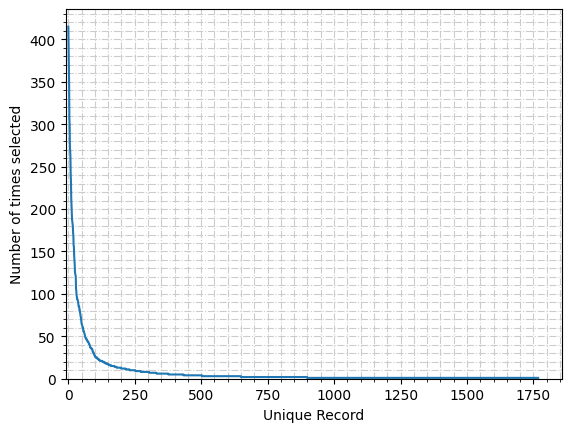

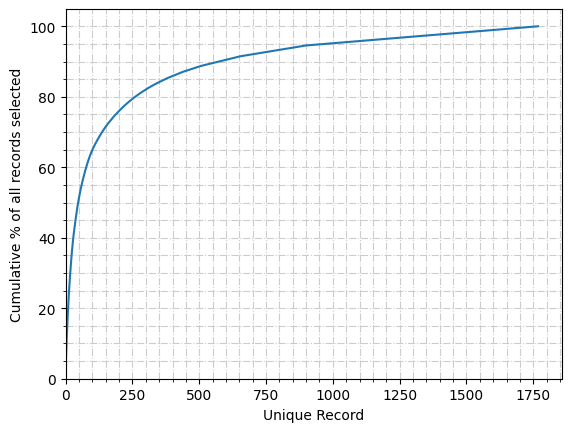

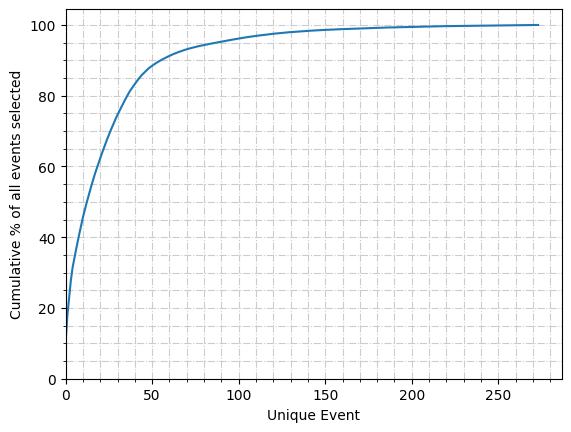

In [6]:
fig, ax3 = plt.subplots()
ax3.plot(recs_and_events["count"].to_numpy())
ax3.grid(True, which="both", ls="-.", color="0.8")
ax3.minorticks_on()
ax3.set_xlabel("Unique Record")
ax3.set_ylabel("Number of times selected")
ax3.set_ylim(0)
ax3.set_xlim(-10)

fig, ax1 = plt.subplots()
ax1.plot(recs_and_events["cum_%"].to_numpy())
ax1.grid(True, which="both", ls="-.", color="0.8")
ax1.minorticks_on()
ax1.set_xlabel("Unique Record")
ax1.set_ylabel("Cumulative % of all records selected")
ax1.set_ylim(0)
ax1.set_xlim(0)

fig, ax2 = plt.subplots()
ax2.plot(events["cum_%"].to_numpy())
ax2.grid(True, which="both", ls="-.", color="0.8")
ax2.minorticks_on()
ax2.set_xlabel("Unique Event")
ax2.set_ylabel("Cumulative % of all events selected")
ax2.set_ylim(0)
ax2.set_xlim(0)


## Records to download / convert

In [7]:
cols_to_keep = [("metadata", "event_id"), ("metadata", "station_code"), ("metadata", "location_code")]
unique_esm_records = all_recs[all_recs[("metadata", "database")] == "ESM"]\
                     .drop_duplicates(subset=cols_to_keep)
unique_esm_records = unique_esm_records[cols_to_keep].reset_index(drop=True)
esm_records_selected = unique_esm_records
esm_records_selected.to_csv(esm_records_selected_fp, index=False)
write_manifest(esm_records_selected_fp, csv_provenance)

WindowsPath('C:/Users/clemettn/Documents/phd/data_processed/06_gm_selection/AvgSA_03_optimised__mu_sigma/AvgSA_03_summary_esm_records_selected.csv.manifest.json')

In [8]:
# For the NGASub records we need the NGAsubRSN for each combination of event_id and station_code
NGASub_records = all_recs[all_recs[("metadata", "database")] == "NGASub"]
unique_NGASub_id_counts = NGASub_records.groupby(
    [("metadata", "event_id"), ("metadata", "station_code")]).size().sort_values(ascending=False)
unique_NGASub_id_counts = unique_NGASub_id_counts.rename("count")

# load the NGASub database
ngasub_fp = cfg["raw_data"]["gm_flatfiles"] / "NGASub_Metadata_SA_rotD50.csv"
ngasub_db = pd.read_csv(ngasub_fp, header=0, encoding="cp1252", dtype=str)
new_index = list(ngasub_db[["NGAsubEQID", "NGAsubSSN"]].itertuples(index=False, name=None))
ngasub_db.index = new_index
ngasub_db = ngasub_db["NGAsubRSN"]

# RSNs to download
rsns_selected = ngasub_db.loc[unique_NGASub_id_counts.index]
rsns_selected = pd.concat([rsns_selected, unique_NGASub_id_counts], axis=1)
rsns_selected.to_csv(ngasub_records_selected_fp, index=False)
write_manifest(ngasub_records_selected_fp, csv_provenance)

WindowsPath('C:/Users/clemettn/Documents/phd/data_processed/06_gm_selection/AvgSA_03_optimised__mu_sigma/AvgSA_03_summary_ngasub_records_selected.csv.manifest.json')

In [9]:
# Per-campaign record-conversion list (record_identifier, component, database, network_code)
# for the AT2/HDF5 -> JSON converters. Combined across campaigns in
# wp1pt3pt8i-organise_records_to_download.
#
# network_code (added 2026-09-30): an ESM HDF5 file can hold the same station code for TWO
# networks (e.g. GE.KTHA and HL.KTHA), and the record identifier {event}_{station}_{location}
# cannot tell them apart. The network the selection actually chose is looked up from the
# selection database by each record's row label (the index of `recs`), which works for stripes
# selected before the column existed as well as after. The lookup also checks that event,
# station and component still agree with the database row.
import phd_project.scripts.WP1_ground_motion_set.manage_flatfiles as mf

all_meta = all_recs["metadata"].copy()
all_meta["network_code"] = mf.network_code_lookup(cfg["proc_data"]["gm_database"], all_recs)

records_to_convert = (
    all_meta[["record_identifier", "component", "database", "network_code"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# The JSON file name is {record_identifier}__{component}.json, with no network in it. That is
# only unambiguous while no (record_identifier, component) was selected from BOTH networks of a
# pair. It is not the case on 2026-09-30; stop loudly if a future selection makes it happen,
# because two different waveforms would then have to share one JSON.
n_nets = (records_to_convert[records_to_convert["database"] == "ESM"]
          .groupby(["record_identifier", "component"])["network_code"].nunique())
if (n_nets > 1).any():
    raise ValueError("These ESM records were selected from more than one network and would "
                     f"share a JSON file name:\n{n_nets[n_nets > 1]}")

records_to_convert.to_csv(records_to_convert_fp, index=False)
# The list now also depends on the database (for network_code), so its hash is recorded too.
# nb 040 verifies only the final_ensembles entry; the extra key does not affect that check.
write_manifest(records_to_convert_fp, fingerprint(
    final_ensembles=final_ensembles_fp, gm_db_file=cfg["proc_data"]["gm_database"]))

WindowsPath('C:/Users/clemettn/Documents/phd/data_processed/06_gm_selection/AvgSA_03_optimised__mu_sigma/AvgSA_03_records_to_convert.csv.manifest.json')